# TP3 · Paso 5 — Modelo final, evaluación en test y predictor

1. Entrenamos el sistema final elegido en el paso 4 sobre **todo train** y lo evaluamos **una única vez** sobre el test reservado en el paso 1 (junto con el baseline, para comparar).
2. Analizamos si las mejoras fueron **globales o específicas de subgrupos**.
3. Estimamos el **rendimiento esperado en datos nuevos**.
4. Reentrenamos con **todos los datos** (train + test) y exportamos `predictor_v1_Grupo_5`.

Para garantizar que lo que evaluamos es exactamente lo que se entrega, el preprocesamiento se hace con las mismas funciones de `predictor_v1_Grupo_5.py` y `exportar_modelo.py` (este último define el modelo final y se usa también para generar los archivos que se entregan).

In [1]:
import importlib
import platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, roc_auc_score

import tp3_comun as C
import predictor_v1_Grupo_5 as P
import exportar_modelo as EM

X_train, y_train = C.cargar_split("train")
X_test, y_test = C.cargar_split("test")
paso2 = joblib.load(C.RESULTADOS / "paso2_baseline.joblib")
paso4 = joblib.load(C.RESULTADOS / "paso4_estrategias.joblib")
HP = {**paso4["HP_BASE"], **paso4["HP_OPT"]}
UMBRAL = paso4["umbral"]
print("Hiperparámetros finales:", {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in HP.items()})
print("Umbral:", UMBRAL)

def entrenar_sistema(X, y):
    # Sistema final: FE + HGB(HP) con peso 1/sqrt(n_lote) + memoria de reservas vistas
    # (misma función que genera los modelos entregados: exportar_modelo.entrenar)
    modelo, memoria = EM.entrenar(X, y)
    return {"modelo": modelo, "memoria": memoria, "umbral": EM.UMBRAL}

def proba_sistema(sis, X):
    Xp = P._preparar(X)
    p = sis["modelo"].predict_proba(P._agregar_features(Xp))[:, 1]
    m = np.array([sis["memoria"].get(k, np.nan) for k in P._clave(Xp)], dtype=float)
    return np.where(np.isnan(m), p, m), ~np.isnan(m)

Hiperparámetros finales: {'class_weight': 'balanced', 'learning_rate': 0.0206, 'max_iter': 643, 'max_leaf_nodes': 159, 'random_state': 42, 'l2_regularization': 0.0046, 'max_features': 0.5, 'min_samples_leaf': 12}
Umbral: 0.49000000000000027


## 1. Evaluación en test (baseline vs. sistema final)

In [2]:
sistema = entrenar_sistema(X_train, y_train)
p_final, vista = proba_sistema(sistema, X_test)
baseline = paso2["modelo"].fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
print(f"Reservas del test idénticas a alguna de train: {vista.mean():.1%}  (el split del paso 1 fue por grupos)")

def bootstrap(y, p, umbral, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    y, idx = np.asarray(y), np.arange(len(y))
    ba, auc = [], []
    for _ in range(n):
        s = rng.choice(idx, len(idx))
        ba.append(balanced_accuracy_score(y[s], p[s] >= umbral)); auc.append(roc_auc_score(y[s], p[s]))
    return np.percentile(ba, [2.5, 97.5]), np.percentile(auc, [2.5, 97.5])

filas = {}
for nombre, p, th in [("Baseline (HGB, 28 orig.)", p_base, 0.5), ("Sistema final", p_final, UMBRAL)]:
    ci_ba, ci_auc = bootstrap(y_test, p, th)
    pred = p >= th
    filas[nombre] = {"BA test": balanced_accuracy_score(y_test, pred), "IC95 BA": f"[{ci_ba[0]:.3f}, {ci_ba[1]:.3f}]",
                     "AUC test": roc_auc_score(y_test, p), "IC95 AUC": f"[{ci_auc[0]:.3f}, {ci_auc[1]:.3f}]",
                     "TPR": pred[y_test == 1].mean(), "TNR": 1 - pred[y_test == 0].mean()}
tabla_test = pd.DataFrame(filas).T
tabla_test

Reservas del test idénticas a alguna de train: 0.0%  (el split del paso 1 fue por grupos)


,BA test,IC95 BA,AUC test,IC95 AUC,TPR,TNR
"Baseline (HGB, 28 orig.)",0.856191,"[0.849, 0.863]",0.9383,"[0.934, 0.943]",0.81973,0.892652
Sistema final,0.858459,"[0.851, 0.866]",0.940483,"[0.936, 0.945]",0.827491,0.889427


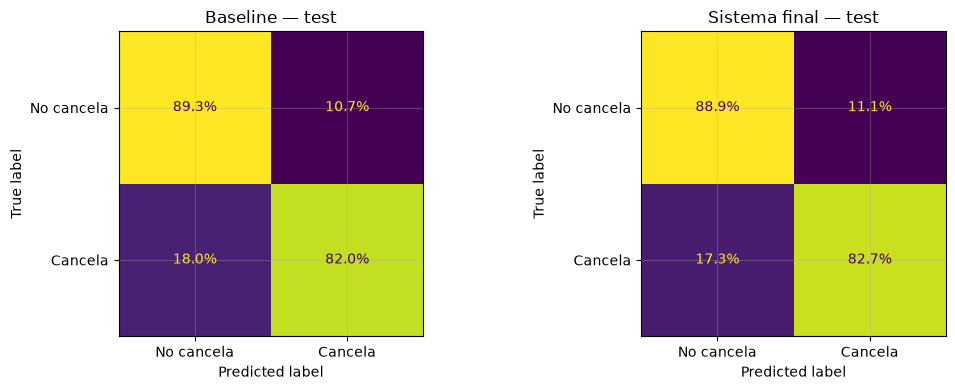

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nombre, p, th) in zip(axes, [("Baseline", p_base, 0.5), ("Sistema final", p_final, UMBRAL)]):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= th).astype(int), ax=ax, normalize="true",
                                            values_format=".1%", display_labels=["No cancela", "Cancela"], colorbar=False)
    ax.set_title(f"{nombre} — test")
fig.tight_layout(); C.guardar(fig, "14_confusion_test.png"); plt.show()

### Tabla resumen de estadísticas finales

Reunimos en una sola tabla las métricas de los dos modelos en sus tres niveles de evaluación:
- **Train:** el modelo predice las mismas reservas con las que se entrenó (100 % de train). Para el sistema final se mide **sin** la memoria de reservas vistas; con ella, train daría ≈ 1 y no tendría sentido.
- **Validación (CV):** CV 5-fold por grupos dentro de train (notebooks 02 y 04).
- **Test:** el 20 % reservado, evaluado una única vez.
- **Brecha** = train − test, el diagnóstico de sobreajuste.

In [4]:
tabla_aj = paso2["tabla_aj"]
tabla_e = paso4["tabla"]
p_base_tr = baseline.predict_proba(X_train)[:, 1]
p_final_tr = sistema["modelo"].predict_proba(P._agregar_features(P._preparar(X_train)))[:, 1]

def fila(p_tr, p_te, th, ba_val, auc_val, ci):
    ba_tr, ba_te = balanced_accuracy_score(y_train, p_tr >= th), balanced_accuracy_score(y_test, p_te >= th)
    auc_tr, auc_te = roc_auc_score(y_train, p_tr), roc_auc_score(y_test, p_te)
    pred = p_te >= th
    return {"BA train": ba_tr, "BA validación (CV)": ba_val, "BA test": ba_te, "IC95 BA test": ci["IC95 BA"],
            "Brecha BA (train−test)": ba_tr - ba_te,
            "AUC train": auc_tr, "AUC validación (CV)": auc_val, "AUC test": auc_te, "IC95 AUC test": ci["IC95 AUC"],
            "Brecha AUC (train−test)": auc_tr - auc_te,
            "TPR test (recall cancel.)": pred[y_test == 1].mean(), "TNR test (especificidad)": 1 - pred[y_test == 0].mean(),
            "Umbral": th}

resumen = pd.DataFrame({
    "Baseline (HGB, 28 orig.)": fila(p_base_tr, p_base, 0.5,
                                     tabla_aj.loc["HGB ajustado", "val_bal_acc"], tabla_aj.loc["HGB ajustado", "val_roc_auc"],
                                     tabla_test.loc["Baseline (HGB, 28 orig.)"]),
    "Sistema final": fila(p_final_tr, p_final, UMBRAL,
                          tabla_e.loc["E5 · E3 + umbral óptimo", "BA"], tabla_e.loc["E5 · E3 + umbral óptimo", "AUC"],
                          tabla_test.loc["Sistema final"]),
})
resumen["Δ (final − baseline)"] = [b2 - b1 if isinstance(b1, float) else "" for b1, b2 in
                                   zip(resumen.iloc[:, 0], resumen.iloc[:, 1])]
C.RESULTADOS.mkdir(exist_ok=True)
resumen.to_csv(C.RESULTADOS / "estadisticas_finales.csv")
resumen.map(lambda v: f"{v:+.4f}" if isinstance(v, float) and v < 0 else (f"{v:.4f}" if isinstance(v, float) else v))

,"Baseline (HGB, 28 orig.)",Sistema final,Δ (final − baseline)
BA train,0.9462,0.9587,0.0125
BA validación (CV),0.8524,0.8563,0.0039
BA test,0.8562,0.8585,0.0023
IC95 BA test,"[0.849, 0.863]","[0.851, 0.866]",
Brecha BA (train−test),0.0900,0.1002,0.0102
AUC train,0.9898,0.9928,0.0030
AUC validación (CV),0.9390,0.9420,0.0030
AUC test,0.9383,0.9405,0.0022
IC95 AUC test,"[0.934, 0.943]","[0.936, 0.945]",
Brecha AUC (train−test),0.0515,0.0523,0.0008


**Comparación CV vs. test:** en la CV por grupos el baseline daba 0.852 y el sistema final 0.856. Las cifras de test (tabla de arriba) son la estimación **honesta** sobre reservas que el modelo nunca vio, ni siquiera como duplicado.

## 2. ¿Mejoras globales o por subgrupo?

,cohorte,n,BA baseline,BA final,Δ
0,client_type = cloud_marketplace,4627,0.7917,0.7984,0.0067
1,client_type = enterprise_client,334,0.8403,0.8211,-0.0192
2,client_type = independent_client,784,0.6082,0.6283,0.0201
3,client_type = managed_account,1958,0.9010,0.9006,-0.0004
4,client_type = research_consortium,1777,0.9625,0.9426,-0.0198
5,service_tier = basic,1264,0.7816,0.7762,-0.0054
6,service_tier = priority,892,0.8889,0.8846,-0.0043
7,service_tier = standard,7417,0.8641,0.8682,0.0041
8,reserved_gpu_type = GPU_T1,7570,0.8728,0.8727,-0.0001
9,reserved_gpu_type = GPU_T2,123,0.8090,0.8312,0.0222


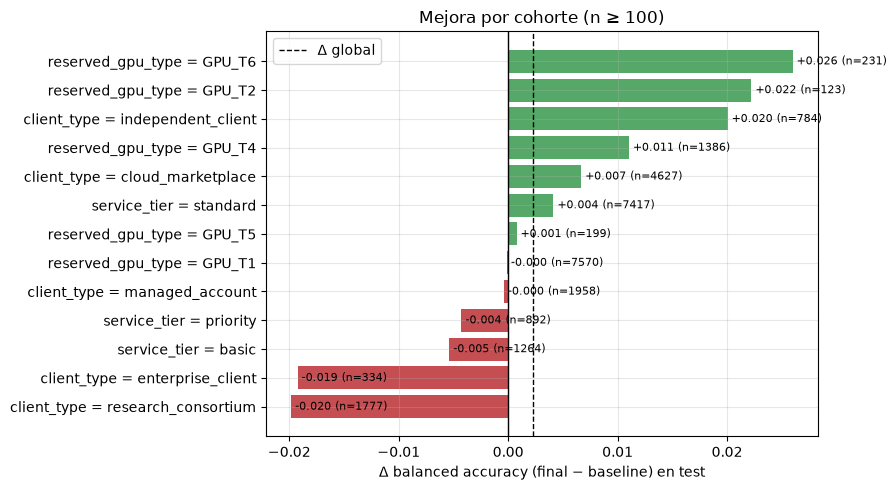

In [5]:
df_t = X_test.copy()
df_t["y"] = y_test.values
filas = []
for col in C.COHORTES:
    for v, g in df_t.groupby(col):
        if len(g) < 100 or g["y"].nunique() < 2:
            continue
        i = g.index
        filas.append({"cohorte": f"{col} = {v}", "n": len(g),
                      "BA baseline": balanced_accuracy_score(g["y"], p_base[i] >= 0.5),
                      "BA final": balanced_accuracy_score(g["y"], p_final[i] >= UMBRAL)})
coh = pd.DataFrame(filas)
coh["Δ"] = coh["BA final"] - coh["BA baseline"]
display(coh.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
c2 = coh.sort_values("Δ")
ax.barh(c2["cohorte"], c2["Δ"], color=np.where(c2["Δ"] >= 0, "#55A868", "#C44E52"))
for i, (d, n) in enumerate(zip(c2["Δ"], c2["n"])):
    ax.text(d, i, f" {d:+.3f} (n={n})", va="center", fontsize=8)
ax.axvline(0, c="k", lw=1)
ax.axvline(tabla_test.loc["Sistema final", "BA test"] - tabla_test.loc["Baseline (HGB, 28 orig.)", "BA test"],
           c="k", ls="--", lw=1, label="Δ global")
ax.set_xlabel("Δ balanced accuracy (final − baseline) en test"); ax.legend()
ax.set_title("Mejora por cohorte (n ≥ 100)")
fig.tight_layout(); C.guardar(fig, "15_mejora_cohortes.png"); plt.show()

**Las mejoras fueron específicas de subgrupos, no globales:**
- Globalmente la ganancia en test es **pequeña: +0.002 BA y +0.002 AUC**. Está dentro de los intervalos de confianza, así que sobre reservas nuevas el sistema final es, como mucho, **marginalmente mejor** que el baseline.
- **Donde sí mejoró es en la cohorte priorizada y en los segmentos minoritarios:**
  - `cloud_marketplace` +0.007, `independent_client` +0.020.
  - GPUs menos frecuentes: `GPU_T4` +0.011, `GPU_T6` +0.026, `GPU_T2` +0.022.
  - `service_tier = standard` +0.004.
- **A cambio, empeoran levemente cohortes que ya se predecían muy bien** (`research_consortium` −0.020, `enterprise_client` −0.019). Es el efecto de la ponderación de lotes: esas cohortes tienen muchas reservas en lote y ahora pesan menos en el entrenamiento.
- **Conclusión:** la estrategia data-centered **redistribuyó** el rendimiento hacia los segmentos con más errores, que era el objetivo de 3.3, pero con la información actual no hay una mejora global grande sobre reservas nuevas.

## 3. Rendimiento esperado en datos nuevos

In [6]:
mem = paso4["tabla_mem"]
ba_test = tabla_test.loc["Sistema final", "BA test"]
print(f"Escenario A — reservas totalmente nuevas (test por grupos): BA ≈ {ba_test:.3f}")
print(f"Escenario B — test extraído al azar de la misma fuente (CV aleatoria, paso 4): "
      f"BA ≈ {mem.loc['E6 · E3 + memoria', 'BA total']:.3f}  "
      f"(vistas {mem.loc['E6 · E3 + memoria', 'BA vistas']:.3f} / no vistas {mem.loc['E6 · E3 + memoria', 'BA no vistas']:.3f})")

Escenario A — reservas totalmente nuevas (test por grupos): BA ≈ 0.858
Escenario B — test extraído al azar de la misma fuente (CV aleatoria, paso 4): BA ≈ 0.886  (vistas 0.988 / no vistas 0.788)


El rendimiento esperado depende de **qué tan parecidas sean las reservas de evaluación a las del dataset**:

| Escenario | Estimación | Fuente |
|---|---|---|
| **A. Reservas nuevas** (ninguna repetida respecto de nuestros datos) | **BA ≈ 0.858** (IC95 0.851–0.866), AUC ≈ 0.940 | Test reservado, aislado por grupos |
| **A'. Reservas nuevas y únicas** (sin lotes de duplicados dentro del propio test) | **BA ≈ 0.79–0.81** | Las reservas únicas son las más difíciles (BA ≈ 0.79 en el análisis de errores) |
| **B. Misma fuente con reservas repetidas** | BA ≈ 0.886 | CV aleatoria del paso 4 |

**Qué indica el leaderboard de la competición (11/11):** los 9 equipos evaluados obtuvieron **BA 0.790–0.828** y **AUC 0.894–0.915**. Si el test secreto repitiera reservas de nuestro dataset (escenario B), equipos con modelos similares estarían en 0.85–0.89. Esto sugiere que el test secreto se parece al **escenario A'**: reservas nuevas, probablemente sin duplicados o de otro período. Por eso:
- La **memoria de reservas vistas** probablemente no aporte en la competición. Se mantiene porque no perjudica: sólo actúa si la reserva es idéntica a una conocida.
- Nuestra estimación **realista para la competición es BA ≈ 0.80–0.83**, en línea con el leaderboard. La diferencia con nuestro test (0.858) se explica por los lotes de duplicados *dentro* de nuestro test, que son más fáciles de predecir.

## 4. Modelo final: reentrenamiento con todos los datos y exportación

Tal como se vio en la clase 11, la validación sirve para **elegir el sistema** (features + algoritmo + hiperparámetros + umbral). Una vez elegido, se reentrena con **todos los datos disponibles** (train + test = 47 842 reservas): el modelo aprende de más ejemplos y la memoria de reservas vistas cubre todo el dataset.

**Compatibilidad entre versiones.** Un modelo de scikit-learn guardado con `joblib` sólo se puede cargar con la misma versión de scikit-learn (y una numpy compatible). Como no sabemos con qué versión se evaluará, ejecutamos `exportar_modelo.py` en entornos con scikit-learn 1.2 a 1.9 (numpy 1.26, que se puede leer también desde numpy 2) y verificamos qué archivo carga en cada versión:

| scikit-learn del evaluador | archivo que usa el predictor |
|---|---|
| 1.2 | `modelo_sklearn_1.2.joblib` |
| 1.3 | `modelo_sklearn_1.3.joblib` |
| 1.4 – 1.5 | `modelo_sklearn_1.4.joblib` |
| 1.6 (Google Colab) | `modelo_sklearn_1.6.joblib` |
| 1.7 | `modelo_sklearn_1.7.joblib` |
| 1.8 – 1.9 | `modelo_sklearn_1.9.joblib` |

El predictor detecta la versión instalada, carga el archivo correspondiente y **verifica** que reproduzca la probabilidad guardada de 5 reservas de control antes de usarlo. Se probó en 11 entornos (scikit-learn 1.2.1 con pandas 1.5 / Python 3.10 hasta scikit-learn 1.9.1 con pandas 3 / Python 3.14). La memoria se guarda como un diccionario de texto (`memoria.pkl.xz`), que no depende de versiones.

(En sklearn < 1.4 el modelo no usa `max_features` porque no existía; en 1.2 tampoco `min_frequency`.)

In [7]:
import os
carpeta = "predictor_v1_Grupo_5_modelos"
filas = []
for n in sorted(os.listdir(carpeta)):
    info = {}
    if n.endswith(".joblib"):
        try:
            info = joblib.load(os.path.join(carpeta, n))["info"]
        except Exception:  # esperado: un modelo de otra versión de sklearn no carga en esta
            info = {"sklearn": n[15:-7] + ".x", "nota": f"no carga en sklearn {sklearn.__version__} (esperado)"}
    filas.append({"archivo": n, "MB": os.path.getsize(os.path.join(carpeta, n)) / 1e6, **info})
pd.DataFrame(filas).round(2)

,archivo,MB,sklearn,nota,grupo,filas,numpy,pandas,python
0,memoria.pkl.xz,0.36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,modelo_sklearn_1.2.joblib,2.86,1.2.x,no carga en sklearn 1.9.1 (esperado),NaN,NaN,NaN,NaN,NaN
2,modelo_sklearn_1.3.joblib,2.18,1.3.x,no carga en sklearn 1.9.1 (esperado),NaN,NaN,NaN,NaN,NaN
3,modelo_sklearn_1.4.joblib,2.93,1.4.x,no carga en sklearn 1.9.1 (esperado),NaN,NaN,NaN,NaN,NaN
4,modelo_sklearn_1.6.joblib,2.93,1.6.x,no carga en sklearn 1.9.1 (esperado),NaN,NaN,NaN,NaN,NaN
5,modelo_sklearn_1.7.joblib,2.93,1.7.x,no carga en sklearn 1.9.1 (esperado),NaN,NaN,NaN,NaN,NaN
6,modelo_sklearn_1.9.joblib,2.62,1.9.1,NaN,5.0,47842.0,1.26.4,2.3.3,3.11.18


## 5. Verificación del predictor (como lo usaría la cátedra)

In [8]:
from predictor_v1_Grupo_5 import predictor_v1_Grupo_5, _cargar

crudo = C.cargar_original()                  # CSV original con las 34 columnas (incluye leakage y target)
y_pred = predictor_v1_Grupo_5(crudo)
print("Archivo de modelo cargado:", _cargar()["archivo"], "| sklearn", sklearn.__version__)
print(type(y_pred), y_pred.shape, np.unique(y_pred))
assert y_pred.shape == (len(crudo),) and set(np.unique(y_pred)) <= {0, 1}

# 1) Las columnas extra / el target no influyen: mismo resultado con sólo las 28 variables
assert np.array_equal(y_pred, predictor_v1_Grupo_5(crudo[C.FEATURES_ORIGINALES]))
# 2) Funciona fila a fila y con columnas en otro orden
assert np.array_equal(y_pred[:5], predictor_v1_Grupo_5(crudo.iloc[:5, ::-1]))
# 3) Reserva totalmente nueva (no está en memoria) -> usa el modelo
nueva = crudo.iloc[[0]].copy(); nueva["hours_before_execution"] = 9999
print("Reserva nueva ->", predictor_v1_Grupo_5(nueva))
# 4) Sobre el test (reservas nuevas para el modelo de la sección 1) el modelo exportado
#    se comporta igual que el evaluado: misma tasa de cancelación predicha
print(f"Tasa de cancelación predicha en el dataset: {y_pred.mean():.3f} (real: {crudo[C.TARGET].mean():.3f})")
print("Verificación OK")

Archivo de modelo cargado: modelo_sklearn_1.9.joblib | sklearn 1.9.1
<class 'numpy.ndarray'> (47842,) [0 1]


Reserva nueva -> [0]
Tasa de cancelación predicha en el dataset: 0.417 (real: 0.417)
Verificación OK


> La balanced accuracy sobre el propio dataset de entrenamiento no es una estimación válida (el sistema ya vio esas reservas); la estimación honesta es la de la sección 3.

## Conclusiones finales

1. **Datos y validación:** el factor más importante del TP no fue el modelo sino **cómo tratar los datos**.
   - Detectamos fuga directa (`execution_status`) y un 33 % de reservas duplicadas.
   - Si no se valida por grupos, las métricas se inflan ~3 puntos.
   - Elegir bien el split (clase 11) tuvo más impacto que elegir entre modelos.
2. **Model-centered:** los ensembles de árboles dominan (≈ 0.85). Ajustar hiperparámetros y combinar modelos dio mejoras **pequeñas** (+0.004 en CV) porque el sistema está limitado por la **información en X**: la validación se estanca con más datos y hay errores indistinguibles con las variables actuales.
3. **Data-centered:**
   - El análisis de errores mostró que `cloud_marketplace` (49 % de los datos) concentra el 73 % de los errores.
   - Las intervenciones sobre los datos (features nuevas y ponderación de lotes) mejoraron justamente esa cohorte y los segmentos minoritarios.
   - La memoria de reservas repetidas sólo ayuda si el set de evaluación comparte reservas con el dataset, lo que el leaderboard sugiere que no ocurre.
4. **Rendimiento esperado:**
   - **Test propio:** BA 0.858 y AUC 0.940.
   - **Competición:** estimación realista **≈ 0.80–0.83**, por la mayor proporción de reservas únicas y nuevas.
5. **Siguiente paso con más impacto:** **adquirir nuevas variables** (historial por organización/agente, señales de lote, contexto de mercado, ver 3.4), no más filas del mismo tipo.
6. **Despliegue (clase 12, MLOps):**
   - `predictor_v1_Grupo_5.py` + carpeta `predictor_v1_Grupo_5_modelos/` (~17 MB, sólo scikit-learn).
   - Como los modelos de scikit-learn no son portables entre versiones, se exportó un modelo por versión (1.2 a 1.9). El predictor elige el adecuado y lo valida con reservas de control antes de usarlo.
   - Recibe el DataFrame de reservas (ignora columnas extra y el target) y devuelve un array de 0/1.